# Team 4 — Student Success & At-Risk Prediction
## Data Cleaning and Exploratory Data Analysis (EDA)

**Goal:** inspect the CSV, validate and clean it conservatively, explore feature distributions and relationships, and export a cleaned copy. Model training is intentionally **not** included yet.

### Important dataset caveat
In the CSV previously inspected for this project, `At_Risk` matched the rule `Risk_Score >= 50` for every row. The notebook checks this again. If confirmed, **do not use `Risk_Score` as a model input**, because it directly defines the target and would cause target leakage. The CSV itself does not establish the original data source or how the target was produced, so verify provenance before presenting the rows as real observed student data.

**How to use:** run the cells from top to bottom. When prompted, upload your `student_at_risk_dataset.csv` file.

In [ ]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid", context="notebook")

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
# 2. Upload the CSV into Google Colab
from google.colab import files

uploaded = files.upload()
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("No CSV file was uploaded. Please upload your student at-risk CSV.")

csv_path = csv_files[0]
df_raw = pd.read_csv(csv_path)
print(f"Loaded: {csv_path}")
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")

Saving student_at_risk_cleaned.csv to student_at_risk_cleaned.csv
Loaded: student_at_risk_cleaned.csv
Rows: 50,000 | Columns: 30


In [ ]:
# 3. First look at the raw data
display(df_raw.head())
print("\nColumn names:")
print(df_raw.columns.tolist())
print("\nData types and non-null counts:")
df_raw.info()

,Student_ID,Age,Gender,Stream,10th_Percentage,12th_Percentage,Math_Score,Science_Score,English_Score,Social_Studies_Score,Business_Studies_Score,Computer_Science_Score,Logical_Reasoning_Score,Numerical_Aptitude_Score,Verbal_Reasoning_Score,Spatial_Aptitude_Score,Abstract_Reasoning_Score,Mechanical_Reasoning_Score,Perceptual_Speed_Score,Analytical_Thinking,Creativity_Level,Attention_to_Detail,Communication_Skills,Higher_Education_Interest,Attendance_Percentage,Assignment_Completion_Percentage,Previous_Semester_GPA,Previous_Assessment_Score,Risk_Score,At_Risk
0,STU_00001,18,Female,Commerce,94.9,96.0,85.2,78.1,71.9,69.8,98.8,75.9,66.0,61.0,56.0,66.7,58.0,59.3,65.4,6,6,8,4,Medium,86.4,91.8,9.57,88.3,0,0
1,STU_00002,20,Male,Commerce,60.9,61.0,58.2,53.6,60.9,81.8,59.6,58.2,70.8,47.8,63.2,73.7,49.4,66.6,56.7,4,7,4,6,Medium,66.3,59.0,9.63,81.6,0,0
2,STU_00003,19,Male,Science,86.2,83.3,85.8,99.5,79.0,75.0,76.1,95.3,80.4,77.4,79.9,63.3,85.0,74.3,85.9,8,4,7,6,Medium,91.5,72.9,6.75,62.6,0,0
3,STU_00004,18,Female,Commerce,76.6,72.8,71.5,83.0,69.5,63.1,78.2,74.9,72.8,69.0,68.4,69.8,74.0,84.0,70.6,6,6,6,4,Low,81.8,39.9,4.76,70.1,50,1
4,STU_00005,17,Male,Science,55.8,68.6,50.5,74.7,54.6,67.4,59.4,75.0,33.9,30.6,32.6,32.0,51.0,38.6,49.9,2,4,5,4,High,45.7,66.9,8.18,80.0,30,0



Column names:
['Student_ID', 'Age', 'Gender', 'Stream', '10th_Percentage', '12th_Percentage', 'Math_Score', 'Science_Score', 'English_Score', 'Social_Studies_Score', 'Business_Studies_Score', 'Computer_Science_Score', 'Logical_Reasoning_Score', 'Numerical_Aptitude_Score', 'Verbal_Reasoning_Score', 'Spatial_Aptitude_Score', 'Abstract_Reasoning_Score', 'Mechanical_Reasoning_Score', 'Perceptual_Speed_Score', 'Analytical_Thinking', 'Creativity_Level', 'Attention_to_Detail', 'Communication_Skills', 'Higher_Education_Interest', 'Attendance_Percentage', 'Assignment_Completion_Percentage', 'Previous_Semester_GPA', 'Previous_Assessment_Score', 'Risk_Score', 'At_Risk']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 30 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Student_ID                        50000 non-null  object 


In [ ]:
# 4. Initial data-quality checks
quality_before = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2),
    "unique_values": df_raw.nunique(dropna=False),
}).sort_values("missing_count", ascending=False)

display(quality_before)
print(f"\nExact duplicate rows: {df_raw.duplicated().sum():,}")
if "Student_ID" in df_raw.columns:
    print(f"Duplicate Student_ID values: {df_raw['Student_ID'].duplicated().sum():,}")

,dtype,missing_count,missing_percent,unique_values
Student_ID,object,0,0.0,50000
Age,int64,0,0.0,5
Gender,object,0,0.0,3
Stream,object,0,0.0,3
10th_Percentage,float64,0,0.0,513
12th_Percentage,float64,0,0.0,536
Math_Score,float64,0,0.0,642
Science_Score,float64,0,0.0,643
English_Score,float64,0,0.0,585
Social_Studies_Score,float64,0,0.0,634



Exact duplicate rows: 0
Duplicate Student_ID values: 0


## Data cleaning

This section performs conservative cleaning: trim whitespace, normalize category text, convert expected numeric columns, remove exact duplicate rows, and flag values outside sensible ranges. It does **not** delete statistical outliers merely because they look extreme. Missing feature values are left missing for now; model-stage imputation should be fitted on training data only.

In [ ]:
# 5. Create a cleaned copy and standardize text

df_clean = df_raw.copy()
df_clean.columns = df_clean.columns.astype(str).str.strip()

# Remove leading/trailing whitespace from all text columns.
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Normalize known categorical columns while preserving category meaning.
category_cols = [c for c in ["Gender", "Stream", "Higher_Education_Interest"] if c in df_clean.columns]
for col in category_cols:
    df_clean[col] = df_clean[col].str.title()

# Convert all non-ID, non-category columns to numeric; unexpected values become NaN and are audited.
non_numeric_cols = set(category_cols + (["Student_ID"] if "Student_ID" in df_clean.columns else []))
for col in df_clean.columns:
    if col not in non_numeric_cols:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

rows_before_dedup = len(df_clean)
duplicate_rows_removed = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().copy()
print(f"Exact duplicate rows removed: {duplicate_rows_removed:,}")
print(f"Rows remaining: {len(df_clean):,} (started with {rows_before_dedup:,})")
display(df_clean.head())

Exact duplicate rows removed: 0
Rows remaining: 50,000 (started with 50,000)


,Student_ID,Age,Gender,Stream,10th_Percentage,12th_Percentage,Math_Score,Science_Score,English_Score,Social_Studies_Score,Business_Studies_Score,Computer_Science_Score,Logical_Reasoning_Score,Numerical_Aptitude_Score,Verbal_Reasoning_Score,Spatial_Aptitude_Score,Abstract_Reasoning_Score,Mechanical_Reasoning_Score,Perceptual_Speed_Score,Analytical_Thinking,Creativity_Level,Attention_to_Detail,Communication_Skills,Higher_Education_Interest,Attendance_Percentage,Assignment_Completion_Percentage,Previous_Semester_GPA,Previous_Assessment_Score,Risk_Score,At_Risk
0,STU_00001,18,Female,Commerce,94.9,96.0,85.2,78.1,71.9,69.8,98.8,75.9,66.0,61.0,56.0,66.7,58.0,59.3,65.4,6,6,8,4,Medium,86.4,91.8,9.57,88.3,0,0
1,STU_00002,20,Male,Commerce,60.9,61.0,58.2,53.6,60.9,81.8,59.6,58.2,70.8,47.8,63.2,73.7,49.4,66.6,56.7,4,7,4,6,Medium,66.3,59.0,9.63,81.6,0,0
2,STU_00003,19,Male,Science,86.2,83.3,85.8,99.5,79.0,75.0,76.1,95.3,80.4,77.4,79.9,63.3,85.0,74.3,85.9,8,4,7,6,Medium,91.5,72.9,6.75,62.6,0,0
3,STU_00004,18,Female,Commerce,76.6,72.8,71.5,83.0,69.5,63.1,78.2,74.9,72.8,69.0,68.4,69.8,74.0,84.0,70.6,6,6,6,4,Low,81.8,39.9,4.76,70.1,50,1
4,STU_00005,17,Male,Science,55.8,68.6,50.5,74.7,54.6,67.4,59.4,75.0,33.9,30.6,32.6,32.0,51.0,38.6,49.9,2,4,5,4,High,45.7,66.9,8.18,80.0,30,0


In [ ]:
# 6. Validate numeric ranges; invalid values are set to missing rather than deleting whole rows
range_rules = {}

for col in df_clean.columns:
    if "Percentage" in col:
        range_rules[col] = (0, 100)
    elif col.endswith("_Score") or col == "Risk_Score":
        range_rules[col] = (0, 100)

if "Previous_Semester_GPA" in df_clean.columns:
    range_rules["Previous_Semester_GPA"] = (0, 10)

for col in ["Analytical_Thinking", "Creativity_Level", "Attention_to_Detail", "Communication_Skills"]:
    if col in df_clean.columns:
        range_rules[col] = (1, 10)

if "Age" in df_clean.columns:
    range_rules["Age"] = (14, 100)  # Broad plausibility bounds for a student dataset.

invalid_range_counts = {}
for col, (lower, upper) in range_rules.items():
    numeric_values = df_clean[col]
    invalid_mask = numeric_values.notna() & ~numeric_values.between(lower, upper)
    invalid_range_counts[col] = int(invalid_mask.sum())
    df_clean.loc[invalid_mask, col] = np.nan

# A binary target must contain only 0 or 1.
if "At_Risk" in df_clean.columns:
    invalid_target_mask = df_clean["At_Risk"].notna() & ~df_clean["At_Risk"].isin([0, 1])
    invalid_range_counts["At_Risk_non_binary"] = int(invalid_target_mask.sum())
    df_clean.loc[invalid_target_mask, "At_Risk"] = np.nan

range_audit = pd.DataFrame({
    "invalid_values_found": pd.Series(invalid_range_counts, dtype="int64")
}).sort_values("invalid_values_found", ascending=False)
print("Values outside validation rules (these were changed to missing):")
display(range_audit)

# Rows without a target cannot be used for supervised modelling; report before removal.
if "At_Risk" in df_clean.columns:
    rows_missing_target = int(df_clean["At_Risk"].isna().sum())
    df_clean = df_clean.dropna(subset=["At_Risk"]).copy()
    df_clean["At_Risk"] = df_clean["At_Risk"].astype("int64")
    print(f"Rows removed because At_Risk was missing/invalid: {rows_missing_target:,}")

print(f"\nCleaned dataset shape: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")

Values outside validation rules (these were changed to missing):


,invalid_values_found
10th_Percentage,0
12th_Percentage,0
Math_Score,0
Science_Score,0
English_Score,0
Social_Studies_Score,0
Business_Studies_Score,0
Computer_Science_Score,0
Logical_Reasoning_Score,0
Numerical_Aptitude_Score,0


Rows removed because At_Risk was missing/invalid: 0

Cleaned dataset shape: 50,000 rows × 30 columns


In [ ]:
# 7. Check data quality after cleaning
quality_after = pd.DataFrame({
    "dtype": df_clean.dtypes.astype(str),
    "missing_count": df_clean.isna().sum(),
    "missing_percent": (df_clean.isna().mean() * 100).round(2),
    "unique_values": df_clean.nunique(dropna=False),
}).sort_values("missing_count", ascending=False)

display(quality_after)
print(f"Exact duplicate rows remaining: {df_clean.duplicated().sum():,}")
if "Student_ID" in df_clean.columns:
    print(f"Duplicate Student_ID values remaining: {df_clean['Student_ID'].duplicated().sum():,}")

print("\nNote: missing feature values, if any, are intentionally not filled during EDA.")

,dtype,missing_count,missing_percent,unique_values
Student_ID,string,0,0.0,50000
Age,float64,0,0.0,5
Gender,string,0,0.0,3
Stream,string,0,0.0,3
10th_Percentage,float64,0,0.0,513
12th_Percentage,float64,0,0.0,536
Math_Score,float64,0,0.0,642
Science_Score,float64,0,0.0,643
English_Score,float64,0,0.0,585
Social_Studies_Score,float64,0,0.0,634


Exact duplicate rows remaining: 0
Duplicate Student_ID values remaining: 0

Note: missing feature values, if any, are intentionally not filled during EDA.


## Exploratory Data Analysis (EDA)

Use the charts to understand the target balance, feature distributions, group-level patterns, and possible relationships. These are descriptive findings, not evidence of causation.

In [ ]:
# 8. Dataset overview and descriptive statistics
print(f"Observations: {df_clean.shape[0]:,}")
print(f"Features/columns (including ID and target): {df_clean.shape[1]}")

numeric_summary = df_clean.describe(include=[np.number]).T.round(2)
display(numeric_summary)

categorical_summary = df_clean.select_dtypes(include=["object", "string", "category"]).describe().T
display(categorical_summary)

Observations: 50,000
Features/columns (including ID and target): 30


,count,mean,std,min,25%,50%,75%,max
Age,50000.0,18.28,0.96,17.0,18.00,18.00,19.00,21.0
10th_Percentage,50000.0,73.95,10.17,48.0,67.00,74.00,80.90,99.2
12th_Percentage,50000.0,73.45,12.45,46.0,64.80,73.50,82.20,99.5
Math_Score,50000.0,71.04,11.90,35.0,63.00,71.20,79.10,99.5
Science_Score,50000.0,75.55,14.32,35.0,65.00,75.60,86.70,99.5
English_Score,50000.0,73.65,10.36,40.0,66.60,73.70,80.70,99.0
Social_Studies_Score,50000.0,71.99,13.26,35.0,62.40,70.60,81.30,99.0
Business_Studies_Score,50000.0,72.22,13.70,35.0,62.30,71.00,81.90,99.0
Computer_Science_Score,50000.0,72.03,11.63,35.0,64.20,72.20,80.00,99.5
Logical_Reasoning_Score,50000.0,68.79,12.89,25.0,60.00,68.90,77.50,99.0


,count,unique,top,freq
Student_ID,50000,50000,STU_49985,1
Gender,50000,3,Male,24881
Stream,50000,3,Science,22838
Higher_Education_Interest,50000,3,Medium,19890


,count,percentage
Not at risk (0),32467,64.93
At risk (1),17533,35.07


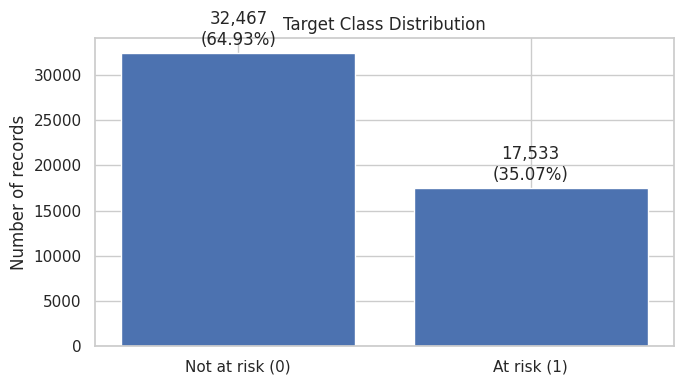

In [ ]:
# 9. Target distribution
if "At_Risk" not in df_clean.columns:
    raise KeyError("Expected target column 'At_Risk' was not found.")

target_counts = df_clean["At_Risk"].value_counts().reindex([0, 1], fill_value=0)
target_pct = (target_counts / target_counts.sum() * 100).round(2)
target_summary = pd.DataFrame({"count": target_counts, "percentage": target_pct})
target_summary.index = ["Not at risk (0)", "At risk (1)"]
display(target_summary)

fig, ax = plt.subplots(figsize=(7, 4))
labels = ["Not at risk (0)", "At risk (1)"]
bars = ax.bar(labels, target_counts.values)
ax.set_title("Target Class Distribution")
ax.set_ylabel("Number of records")
ax.bar_label(bars, labels=[f"{n:,}\n({p:.2f}%)" for n, p in zip(target_counts.values, target_pct.values)], padding=3)
plt.tight_layout()
plt.show()

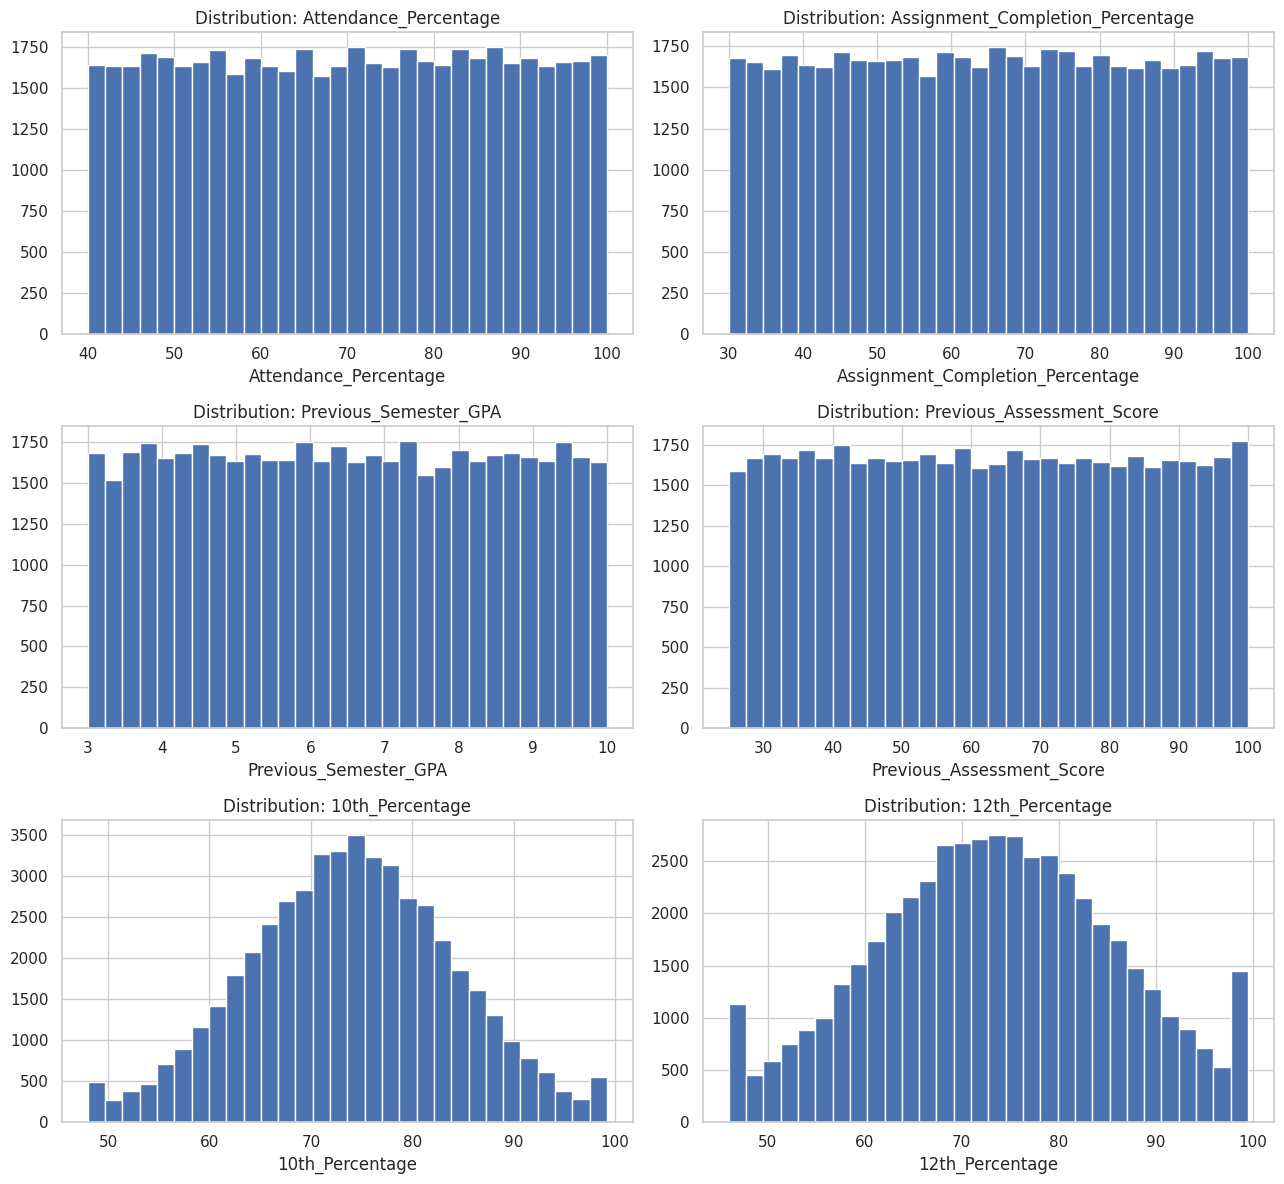

In [ ]:
# 10. Distribution of key numeric features
selected_numeric = [
    "Attendance_Percentage",
    "Assignment_Completion_Percentage",
    "Previous_Semester_GPA",
    "Previous_Assessment_Score",
    "10th_Percentage",
    "12th_Percentage",
]
selected_numeric = [c for c in selected_numeric if c in df_clean.columns]

if selected_numeric:
    ncols = 2
    nrows = int(np.ceil(len(selected_numeric) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, selected_numeric):
        ax.hist(df_clean[col].dropna(), bins=30, edgecolor="white")
        ax.set_title(f"Distribution: {col}")
        ax.set_xlabel(col)
    for ax in axes[len(selected_numeric):]:
        ax.remove()
    plt.tight_layout()
    plt.show()
else:
    print("No selected numeric columns found; check the CSV schema.")

Attendance_Percentage               Assignment_Completion_Percentage  \
                         mean median    std                             mean   
At_Risk                                                                        
0                       76.23   77.9  15.51                            69.77   
1                       58.61   55.6  14.42                            56.24   

                      Previous_Semester_GPA               \
        median    std                  mean median   std   
At_Risk                                                    
0         70.7  18.38                  7.05   7.24  1.90   
1         48.7  20.44                  5.48   5.07  1.84   

        Previous_Assessment_Score                
                             mean median    std  
At_Risk                                          
0                           64.06   64.4  21.12  
1                           59.44   58.2  22.38

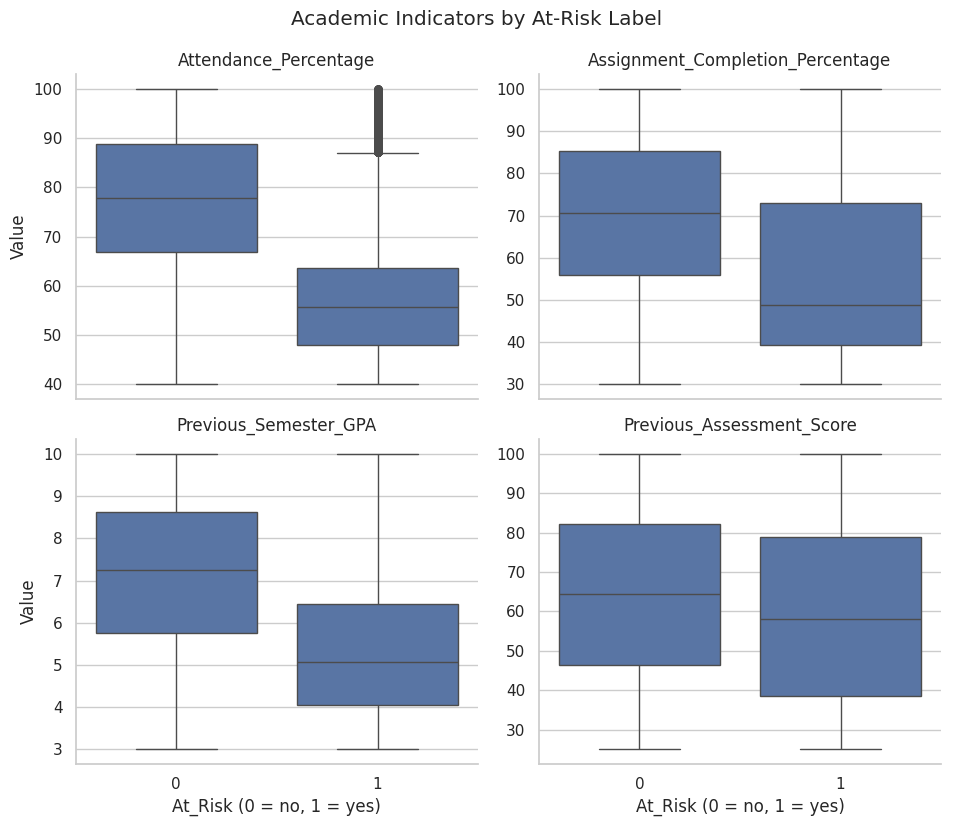

In [ ]:
# 11. Compare important academic indicators by At_Risk (exclude Risk_Score here because it defines the label)
compare_cols = [
    "Attendance_Percentage",
    "Assignment_Completion_Percentage",
    "Previous_Semester_GPA",
    "Previous_Assessment_Score",
]
compare_cols = [c for c in compare_cols if c in df_clean.columns]

if compare_cols:
    display(df_clean.groupby("At_Risk")[compare_cols].agg(["mean", "median", "std"]).round(2))
    plot_df = df_clean.melt(id_vars="At_Risk", value_vars=compare_cols,
                            var_name="Feature", value_name="Value")
    g = sns.catplot(data=plot_df, x="At_Risk", y="Value", col="Feature",
                    kind="box", col_wrap=2, sharey=False, height=4, aspect=1.2)
    g.set_axis_labels("At_Risk (0 = no, 1 = yes)", "Value")
    g.set_titles("{col_name}")
    g.fig.suptitle("Academic Indicators by At-Risk Label", y=1.03)
    plt.show()

In [ ]:
# 12. Check whether Risk_Score directly defines At_Risk (critical leakage check)
if {"Risk_Score", "At_Risk"}.issubset(df_clean.columns):
    derived_target = (df_clean["Risk_Score"] >= 50).astype(int)
    matches = int((derived_target == df_clean["At_Risk"]).sum())
    total = len(df_clean)
    match_rate = matches / total if total else np.nan
    print(f"Rows where (Risk_Score >= 50) matches At_Risk: {matches:,}/{total:,} ({match_rate:.2%})")
    display(pd.crosstab(df_clean["Risk_Score"] >= 50, df_clean["At_Risk"],
                        rownames=["Risk_Score >= 50"], colnames=["At_Risk"]))
    if total and match_rate == 1.0:
        print("WARNING: Risk_Score exactly determines At_Risk in this dataset. Do NOT use Risk_Score as a model feature.")
    else:
        print("The simple threshold does not perfectly reproduce At_Risk. Still investigate how the label was created before modelling.")
else:
    print("Risk_Score or At_Risk column not found; skip this check and verify column names.")

Rows where (Risk_Score >= 50) matches At_Risk: 50,000/50,000 (100.00%)


At_Risk,0,1
Risk_Score >= 50,,
False,32467,0
True,0,17533


,at_risk_rate,records,at_risk_rate_pct
Stream,,,
Humanities,0.359224,13145,35.92
Commerce,0.354284,14017,35.43
Science,0.343506,22838,34.35


,at_risk_rate,records,at_risk_rate_pct
Gender,,,
Other,0.357518,951,35.75
Female,0.352987,24168,35.30
Male,0.348137,24881,34.81


,at_risk_rate,records,at_risk_rate_pct
Higher_Education_Interest,,,
Medium,0.351684,19890,35.17
High,0.350686,15233,35.07
Low,0.349264,14877,34.93


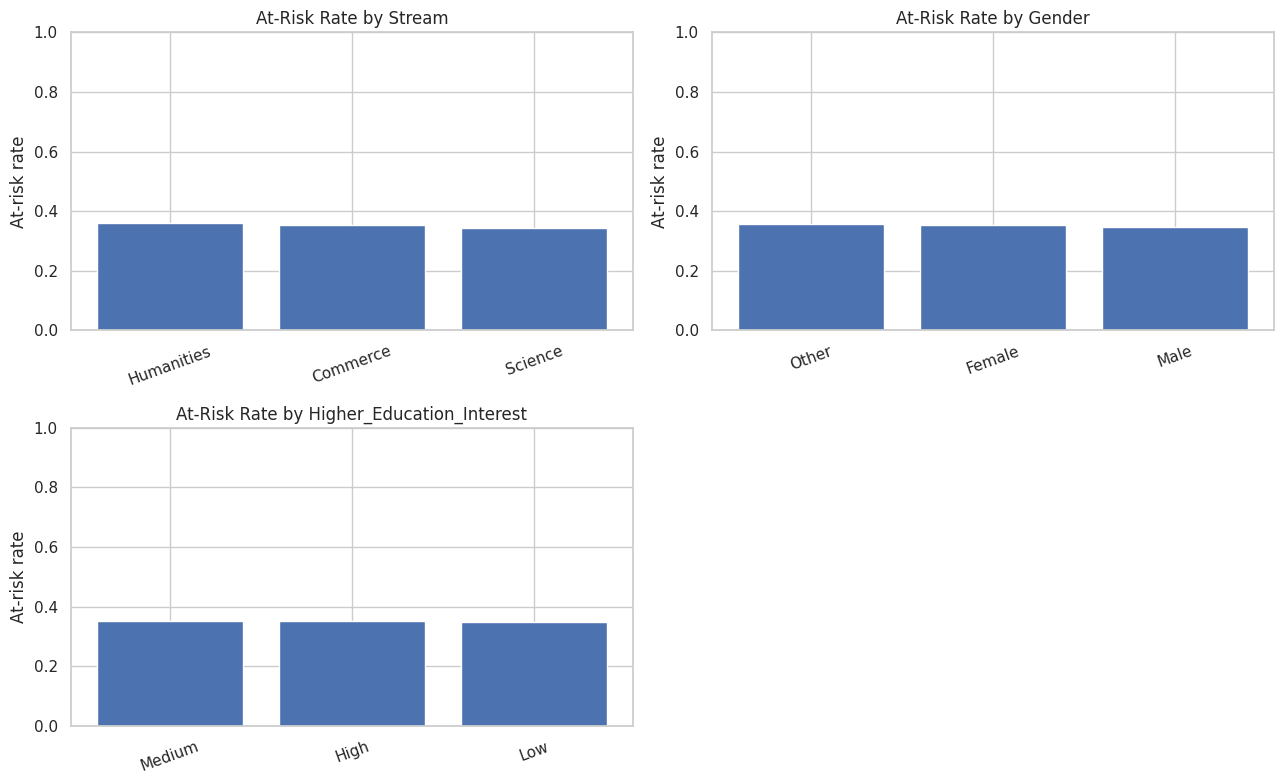

These group comparisons are for understanding the data and reviewing potential bias, not for assuming cause-and-effect.


In [ ]:
# 13. At-risk rate by categorical groups (descriptive/fairness audit only)
cat_audit_cols = [c for c in ["Stream", "Gender", "Higher_Education_Interest"] if c in df_clean.columns]

if cat_audit_cols:
    ncols = 2
    nrows = int(np.ceil(len(cat_audit_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, cat_audit_cols):
        rate_table = (df_clean.groupby(col, dropna=False)["At_Risk"]
                      .agg(at_risk_rate="mean", records="size")
                      .sort_values("at_risk_rate", ascending=False))
        display(rate_table.assign(at_risk_rate_pct=(rate_table["at_risk_rate"] * 100).round(2)))
        ax.bar(rate_table.index.astype(str), rate_table["at_risk_rate"].values)
        ax.set_title(f"At-Risk Rate by {col}")
        ax.set_ylabel("At-risk rate")
        ax.set_ylim(0, 1)
        ax.tick_params(axis="x", rotation=20)
    for ax in axes[len(cat_audit_cols):]:
        ax.remove()
    plt.tight_layout()
    plt.show()
    print("These group comparisons are for understanding the data and reviewing potential bias, not for assuming cause-and-effect.")

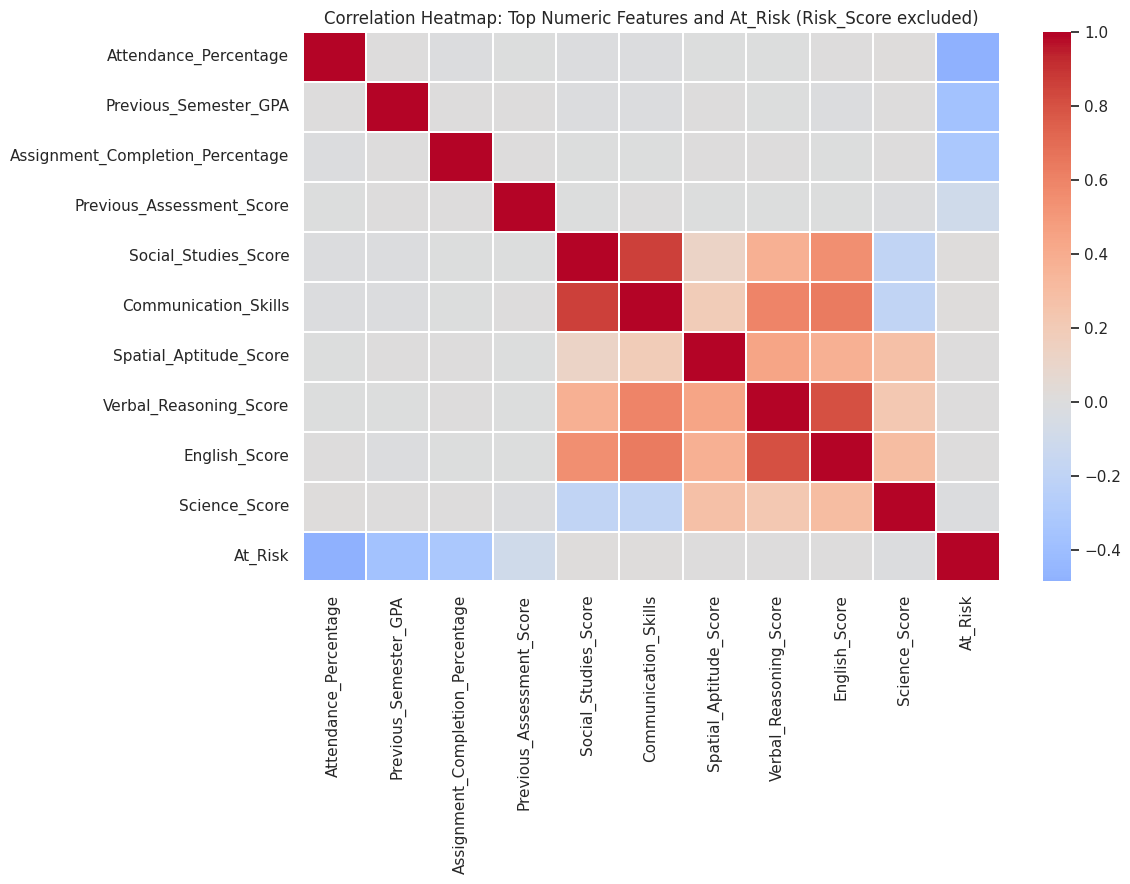

,correlation_with_At_Risk
Attendance_Percentage,-0.486
Previous_Semester_GPA,-0.370
Assignment_Completion_Percentage,-0.320
Previous_Assessment_Score,-0.102
Social_Studies_Score,0.015
Communication_Skills,0.013
Spatial_Aptitude_Score,0.007
Verbal_Reasoning_Score,0.007
English_Score,0.006
Science_Score,-0.006


In [ ]:
# 14. Correlation heatmap for numeric features and target (Risk_Score deliberately excluded)
num_for_corr = df_clean.select_dtypes(include=[np.number]).drop(columns=["Risk_Score"], errors="ignore")

if "At_Risk" in num_for_corr.columns:
    corr_with_target = num_for_corr.corr(numeric_only=True)["At_Risk"].drop("At_Risk", errors="ignore")
    top_features = corr_with_target.abs().sort_values(ascending=False).head(10).index.tolist()
    heatmap_cols = top_features + ["At_Risk"]
    corr_matrix = num_for_corr[heatmap_cols].corr(numeric_only=True)
    plt.figure(figsize=(12, 9))
    sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False, linewidths=0.3)
    plt.title("Correlation Heatmap: Top Numeric Features and At_Risk (Risk_Score excluded)")
    plt.tight_layout()
    plt.show()
    display(corr_with_target.loc[top_features].sort_values(key=lambda s: s.abs(), ascending=False).to_frame("correlation_with_At_Risk").round(3))
else:
    print("At_Risk target is unavailable; skip correlation analysis.")

In [ ]:
# 15. Outlier audit using the IQR rule (flag only; do not automatically delete)
# Risk_Score is excluded because it directly defines the target in this dataset.
outlier_cols = [c for c in df_clean.select_dtypes(include=[np.number]).columns
                if c not in ["At_Risk", "Risk_Score"]]
outlier_rows = []
for col in outlier_cols:
    s = df_clean[col].dropna()
    if len(s) < 4:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append({"column": col, "iqr_lower_bound": lower, "iqr_upper_bound": upper,
                         "potential_outliers": n_out, "percent_of_nonmissing": n_out / len(s) * 100})

outlier_audit = pd.DataFrame(outlier_rows).sort_values("potential_outliers", ascending=False)
display(outlier_audit.head(15).round(2))
print("IQR outliers may be valid students; investigate context before removing any rows.")

,column,iqr_lower_bound,iqr_upper_bound,potential_outliers,percent_of_nonmissing
18,Attention_to_Detail,3.50,7.50,6959,13.92
17,Creativity_Level,3.50,7.50,5386,10.77
0,Age,16.50,20.50,1468,2.94
15,Perceptual_Speed_Score,38.00,97.20,364,0.73
8,Computer_Science_Score,40.50,103.70,207,0.41
3,Math_Score,38.85,103.25,194,0.39
10,Numerical_Aptitude_Score,25.70,108.90,184,0.37
13,Abstract_Reasoning_Score,30.25,101.05,183,0.37
12,Spatial_Aptitude_Score,29.05,101.45,179,0.36
14,Mechanical_Reasoning_Score,25.00,102.60,178,0.36


IQR outliers may be valid students; investigate context before removing any rows.


In [ ]:
# 16. Export cleaned dataset and data-quality report
output_csv = "student_at_risk_cleaned.csv"
output_quality = "student_at_risk_data_quality_report.csv"
output_summary = "student_at_risk_eda_summary.json"

df_clean.to_csv(output_csv, index=False)
quality_after.to_csv(output_quality, index=True)

summary = {
    "input_file": csv_path,
    "rows_after_cleaning": int(df_clean.shape[0]),
    "columns_after_cleaning": int(df_clean.shape[1]),
    "exact_duplicate_rows_removed": int(duplicate_rows_removed),
    "missing_values_remaining_total": int(df_clean.isna().sum().sum()),
    "target_counts": {str(k): int(v) for k, v in df_clean["At_Risk"].value_counts().sort_index().items()},
    "risk_score_threshold_matches_target": None,
}
if {"Risk_Score", "At_Risk"}.issubset(df_clean.columns) and len(df_clean):
    summary["risk_score_threshold_matches_target"] = bool(((df_clean["Risk_Score"] >= 50).astype(int) == df_clean["At_Risk"]).all())

with open(output_summary, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Saved files:")
print(f"- {output_csv}")
print(f"- {output_quality}")
print(f"- {output_summary}")
print("\nSummary:")
print(json.dumps(summary, indent=2))

Saved files:
- student_at_risk_cleaned.csv
- student_at_risk_data_quality_report.csv
- student_at_risk_eda_summary.json

Summary:
{
  "input_file": "student_at_risk_cleaned.csv",
  "rows_after_cleaning": 50000,
  "columns_after_cleaning": 30,
  "exact_duplicate_rows_removed": 0,
  "missing_values_remaining_total": 0,
  "target_counts": {
    "0": 32467,
    "1": 17533
  },
  "risk_score_threshold_matches_target": true
}


In [ ]:
# 17. Download the outputs to your computer (optional)
from google.colab import files
files.download("student_at_risk_cleaned.csv")
files.download("student_at_risk_data_quality_report.csv")
files.download("student_at_risk_eda_summary.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Before modelling — decision checklist

- [ ] Review any remaining missing values in the quality report.
- [ ] Review the distributions and group comparisons for unexpected or impossible values.
- [ ] Investigate the source and generation method for this dataset and the `At_Risk` labels.
- [ ] If `(Risk_Score >= 50)` exactly equals `At_Risk`, keep `Risk_Score` out of model features.
- [ ] Do not treat EDA correlations as causal explanations.
- [ ] During modelling, split train/test before fitting imputers, encoders, scalers, or other learned preprocessing.

**This completes cleaning and EDA only.** It does not train, select, or evaluate a predictive model.

In [ ]:

# STEP 1: Prepare features and split the dataset

from sklearn.model_selection import train_test_split

# 1. Check that the target column exists
if "At_Risk" not in df_clean.columns:
    raise ValueError("The target column 'At_Risk' was not found.")

# 2. Remove rows with missing target values
model_df = df_clean.dropna(subset=["At_Risk"]).copy()

# 3. Separate input features (X) and target (y)
y = model_df["At_Risk"].astype(int)

# Exclude columns that must not be used as model inputs
columns_to_exclude = [
    "At_Risk",       # Target: the value we want to predict
    "Student_ID",    # Identifier, not an academic feature
    "Risk_Score",    # Potential target leakage
    "Gender"         # Excluded to avoid unnecessary sensitive features
]

X = model_df.drop(
    columns=columns_to_exclude,
    errors="ignore"
)

# 4. Check the target labels
if not y.isin([0, 1]).all():
    raise ValueError("At_Risk must contain only 0 and 1.")

if y.nunique() != 2:
    raise ValueError(
        "Both target classes (0 and 1) must be present."
    )

if y.value_counts().min() < 2:
    raise ValueError(
        "Each target class needs at least 2 records for a stratified split."
    )

# 5. Split into training data (80%) and testing data (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 6. Display the results
print("Dataset preparation completed!")
print("-" * 40)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

print("\nFeatures selected for modelling:")
print(X.columns.tolist())


Dataset preparation completed!
----------------------------------------
Training feature shape: (40000, 26)
Testing feature shape: (10000, 26)

Training target distribution:
At_Risk
0    25974
1    14026
Name: count, dtype: int64

Testing target distribution:
At_Risk
0    6493
1    3507
Name: count, dtype: int64

Features selected for modelling:
['Age', 'Stream', '10th_Percentage', '12th_Percentage', 'Math_Score', 'Science_Score', 'English_Score', 'Social_Studies_Score', 'Business_Studies_Score', 'Computer_Science_Score', 'Logical_Reasoning_Score', 'Numerical_Aptitude_Score', 'Verbal_Reasoning_Score', 'Spatial_Aptitude_Score', 'Abstract_Reasoning_Score', 'Mechanical_Reasoning_Score', 'Perceptual_Speed_Score', 'Analytical_Thinking', 'Creativity_Level', 'Attention_to_Detail', 'Communication_Skills', 'Higher_Education_Interest', 'Attendance_Percentage', 'Assignment_Completion_Percentage', 'Previous_Semester_GPA', 'Previous_Assessment_Score']


In [ ]:

# STEP 1A: Corrected preprocessing for numerical and categorical features

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 1. Detect numerical and categorical columns correctly
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

# 2. Preprocessing pipeline for numerical features
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 3. Preprocessing pipeline for categorical features
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 4. Combine both pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# 5. Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# 6. Transform testing data using the same fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing completed successfully!")
print("Training data shape after preprocessing:",
      X_train_processed.shape)
print("Testing data shape after preprocessing:",
      X_test_processed.shape)


Numerical features: ['Age', '10th_Percentage', '12th_Percentage', 'Math_Score', 'Science_Score', 'English_Score', 'Social_Studies_Score', 'Business_Studies_Score', 'Computer_Science_Score', 'Logical_Reasoning_Score', 'Numerical_Aptitude_Score', 'Verbal_Reasoning_Score', 'Spatial_Aptitude_Score', 'Abstract_Reasoning_Score', 'Mechanical_Reasoning_Score', 'Perceptual_Speed_Score', 'Analytical_Thinking', 'Creativity_Level', 'Attention_to_Detail', 'Communication_Skills', 'Attendance_Percentage', 'Assignment_Completion_Percentage', 'Previous_Semester_GPA', 'Previous_Assessment_Score']

Categorical features: ['Stream', 'Higher_Education_Interest']

Preprocessing completed successfully!
Training data shape after preprocessing: (40000, 30)
Testing data shape after preprocessing: (10000, 30)


Choose model (Logistic Regression / Random Forest / Both): both

Training Logistic Regression...

Logistic Regression classification report:
              precision    recall  f1-score   support

 Not At Risk       0.91      0.84      0.88      6493
     At Risk       0.74      0.85      0.79      3507

    accuracy                           0.84     10000
   macro avg       0.83      0.85      0.83     10000
weighted avg       0.85      0.84      0.85     10000



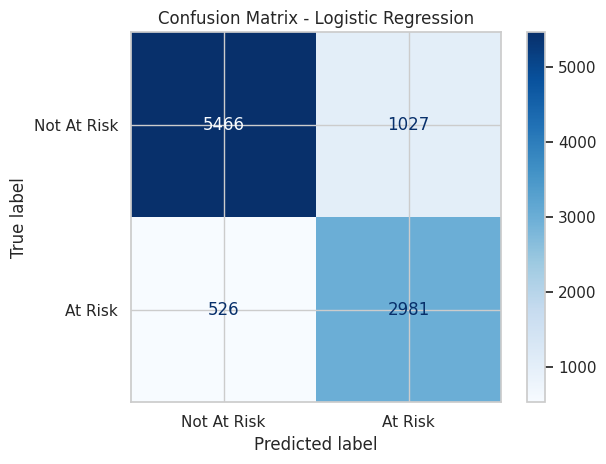


Training Random Forest...

Random Forest classification report:
              precision    recall  f1-score   support

 Not At Risk       1.00      1.00      1.00      6493
     At Risk       1.00      1.00      1.00      3507

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



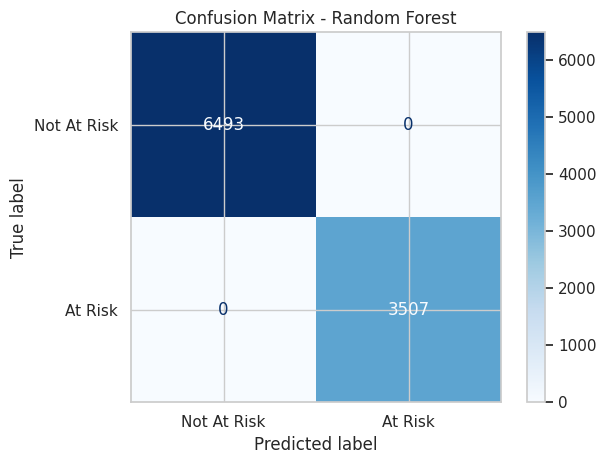


MODEL COMPARISON


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8447,0.7438,0.85,0.7933,0.9322
Random Forest,1.0000,1.0000,1.00,1.0000,1.0000



Highest recall model: Random Forest (Recall = 1.0000)


In [ ]:

# STEP 2: Reproducible model-training pipeline
# Models: Logistic Regression, Random Forest, or Both

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Select the model(s) to train
model_choice = input(
    "Choose model (Logistic Regression / Random Forest / Both): "
).strip().lower()

if model_choice in ["logistic regression", "logistic", "lr"]:
    selected_models = ["Logistic Regression"]

elif model_choice in ["random forest", "rf"]:
    selected_models = ["Random Forest"]

elif model_choice == "both":
    selected_models = ["Logistic Regression", "Random Forest"]

else:
    raise ValueError(
        "Invalid choice. Enter Logistic Regression, Random Forest, or Both."
    )

# 2. Define the models with reproducible settings
model_definitions = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

# 3. Train and evaluate each selected model
for model_name in selected_models:
    print(f"\nTraining {model_name}...")

    # Create a fresh preprocessing + model pipeline
    model_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", model_definitions[model_name])
    ])

    # Fit using training data only
    model_pipeline.fit(X_train, y_train)

    # Predict on the held-out test data
    y_pred = model_pipeline.predict(X_test)
    y_prob = model_pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    trained_models[model_name] = model_pipeline
    results.append(metrics)

    print(f"\n{model_name} classification report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Not At Risk", "At Risk"],
        zero_division=0
    ))

    # Display confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Not At Risk", "At Risk"],
        cmap="Blues"
    )
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

# 4. Compare selected models
results_df = pd.DataFrame(results).set_index("Model")

print("\nMODEL COMPARISON")
display(results_df.round(4))

# 5. Identify the model with the highest recall
best_recall_model = results_df["Recall"].idxmax()

print(
    "\nHighest recall model:",
    best_recall_model,
    f"(Recall = {results_df.loc[best_recall_model, 'Recall']:.4f})"
)


RANDOM FOREST VALIDATION
----------------------------------------
Training accuracy: 1.0
Testing accuracy: 1.0

TOP 15 MOST IMPORTANT FEATURES


,Feature,Importance
20,num__Attendance_Percentage,0.3865
22,num__Previous_Semester_GPA,0.2422
21,num__Assignment_Completion_Percentage,0.2266
23,num__Previous_Assessment_Score,0.0649
6,num__Social_Studies_Score,0.0049
14,num__Mechanical_Reasoning_Score,0.0049
12,num__Spatial_Aptitude_Score,0.0049
11,num__Verbal_Reasoning_Score,0.0048
15,num__Perceptual_Speed_Score,0.0048
8,num__Computer_Science_Score,0.0046


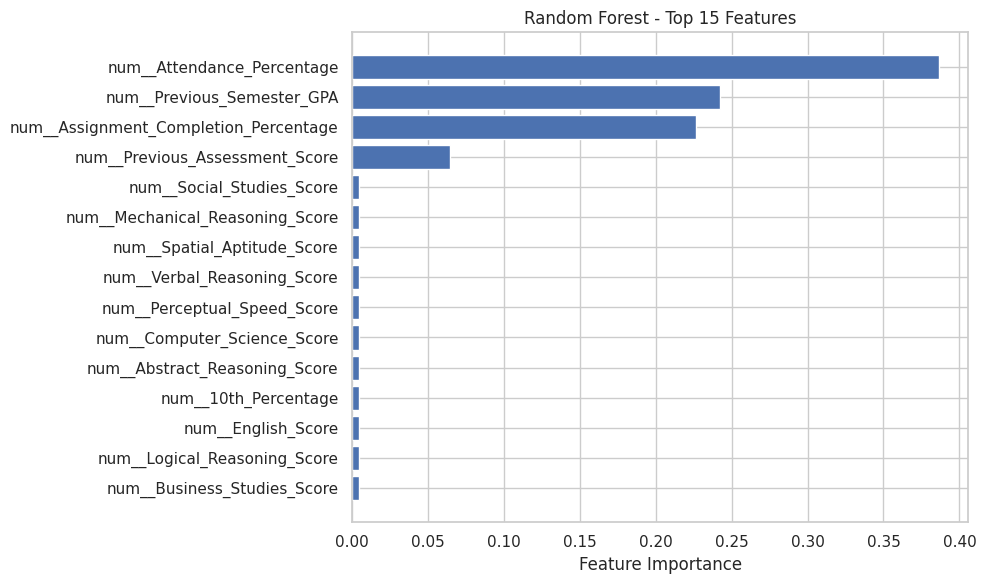

In [ ]:

# STEP 2A: Validate Random Forest results and inspect feature importance

from sklearn.metrics import accuracy_score
import pandas as pd
import matplotlib.pyplot as plt

rf_pipeline = trained_models.get("Random Forest")

if rf_pipeline is None:
    print("Random Forest was not trained. Run Step 2 with 'Both' first.")
else:
    # 1. Compare training and testing performance
    train_pred = rf_pipeline.predict(X_train)
    test_pred = rf_pipeline.predict(X_test)

    print("RANDOM FOREST VALIDATION")
    print("-" * 40)
    print("Training accuracy:",
          round(accuracy_score(y_train, train_pred), 4))
    print("Testing accuracy:",
          round(accuracy_score(y_test, test_pred), 4))

    # 2. Get feature names after preprocessing
    fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]
    rf_model = rf_pipeline.named_steps["model"]

    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = rf_model.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False)

    print("\nTOP 15 MOST IMPORTANT FEATURES")
    display(importance_df.head(15).round(4))

    # 3. Plot feature importance
    top_features = importance_df.head(15).sort_values("Importance")

    plt.figure(figsize=(10, 6))
    plt.barh(top_features["Feature"], top_features["Importance"])
    plt.xlabel("Feature Importance")
    plt.title("Random Forest - Top 15 Features")
    plt.tight_layout()
    plt.show()


In [ ]:

# STEP 2B: Check individual features against the target

check_features = [
    "Assignment_Completion_Percentage",
    "Previous_Assessment_Score",
    "Attendance_Percentage",
    "Previous_Semester_GPA"
]

for col in check_features:
    if col in model_df.columns:
        grouped = model_df.groupby(col)["At_Risk"].nunique()

        print(f"\nFeature: {col}")
        print(
            "Number of feature values associated with both target classes:",
            int((grouped > 1).sum())
        )



Feature: Assignment_Completion_Percentage
Number of feature values associated with both target classes: 701

Feature: Previous_Assessment_Score
Number of feature values associated with both target classes: 751

Feature: Attendance_Percentage
Number of feature values associated with both target classes: 601

Feature: Previous_Semester_GPA
Number of feature values associated with both target classes: 701


In [ ]:

# STEP 2C: Verify Random Forest performance

from sklearn.metrics import accuracy_score, confusion_matrix
import pandas as pd

rf_pipeline = trained_models["Random Forest"]

# Predict on training and testing data
train_predictions = rf_pipeline.predict(X_train)
test_predictions = rf_pipeline.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

print("Random Forest validation results")
print("-" * 40)
print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Testing accuracy:  {test_accuracy:.4f}")

# Check whether any test predictions are incorrect
incorrect = (test_predictions != y_test)

print("\nIncorrect test predictions:", int(incorrect.sum()))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_predictions))

# Show target distribution for incorrect predictions, if any
if incorrect.any():
    error_analysis = pd.DataFrame({
        "Actual": y_test[incorrect],
        "Predicted": test_predictions[incorrect]
    })
    print("\nIncorrect prediction details:")
    display(error_analysis.head(20))
else:
    print("\nEvery test prediction matches the provided target labels.")


Random Forest validation results
----------------------------------------
Training accuracy: 1.0000
Testing accuracy:  1.0000

Incorrect test predictions: 0

Confusion matrix:
[[6493    0]
 [   0 3507]]

Every test prediction matches the provided target labels.


In [ ]:

# STEP 2D: Check whether simple rules reproduce the target

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import accuracy_score

depth_results = []

for depth in range(1, 9):
    rule_model = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    rule_model.fit(X_train, y_train)

    train_pred = rule_model.predict(X_train)
    test_pred = rule_model.predict(X_test)

    depth_results.append({
        "Tree Depth": depth,
        "Training Accuracy": accuracy_score(y_train, train_pred),
        "Testing Accuracy": accuracy_score(y_test, test_pred)
    })

depth_results_df = pd.DataFrame(depth_results)

print("Decision Tree rule-check results:")
display(depth_results_df.round(4))


Decision Tree rule-check results:


,Tree Depth,Training Accuracy,Testing Accuracy
0,1,0.7936,0.7888
1,2,0.8292,0.8266
2,3,0.9670,0.9660
3,4,1.0000,1.0000
4,5,1.0000,1.0000
5,6,1.0000,1.0000
6,7,1.0000,1.0000
7,8,1.0000,1.0000


In [ ]:

# STEP 2E: Display the decision rules

from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Train a depth-4 decision tree
rule_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

rule_pipeline.fit(X_train, y_train)

# Extract transformed feature names and tree model
fitted_preprocessor = rule_pipeline.named_steps["preprocessor"]
decision_tree = rule_pipeline.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

# Print the rules
rules = export_text(
    decision_tree,
    feature_names=list(feature_names),
    decimals=3
)

print("DECISION TREE RULES")
print("=" * 50)
print(rules)


DECISION TREE RULES
|--- num__Attendance_Percentage <= -0.296
|   |--- num__Previous_Semester_GPA <= -0.247
|   |   |--- class: 1
|   |--- num__Previous_Semester_GPA >  -0.247
|   |   |--- num__Assignment_Completion_Percentage <= -0.745
|   |   |   |--- class: 1
|   |   |--- num__Assignment_Completion_Percentage >  -0.745
|   |   |   |--- num__Previous_Assessment_Score <= -1.037
|   |   |   |   |--- class: 1
|   |   |   |--- num__Previous_Assessment_Score >  -1.037
|   |   |   |   |--- class: 0
|--- num__Attendance_Percentage >  -0.296
|   |--- num__Assignment_Completion_Percentage <= -0.745
|   |   |--- num__Previous_Semester_GPA <= -0.247
|   |   |   |--- class: 1
|   |   |--- num__Previous_Semester_GPA >  -0.247
|   |   |   |--- class: 0
|   |--- num__Assignment_Completion_Percentage >  -0.745
|   |   |--- class: 0



In [ ]:
# Check how the main features differ between At_Risk classes

important_features = [
    "Attendance_Percentage",
    "Previous_Semester_GPA",
    "Assignment_Completion_Percentage",
    "Previous_Assessment_Score"
]

print("AVERAGE FEATURE VALUES BY AT-RISK CLASS")
print("=" * 60)

print(
    df_clean.groupby("At_Risk")[important_features]
      .mean()
      .round(2)
)

print("\nTARGET LABEL COUNTS")
print("=" * 60)
print(df_clean["At_Risk"].value_counts())

AVERAGE FEATURE VALUES BY AT-RISK CLASS
         Attendance_Percentage  Previous_Semester_GPA  \
At_Risk                                                 
0                        76.23                   7.05   
1                        58.61                   5.48   

         Assignment_Completion_Percentage  Previous_Assessment_Score  
At_Risk                                                               
0                                   69.77                      64.06  
1                                   56.24                      59.44  

TARGET LABEL COUNTS
At_Risk
0    32467
1    17533
Name: count, dtype: int64


In [ ]:
# Step 3: Compare model performance

print("MODEL PERFORMANCE COMPARISON")
print("=" * 70)

display(
    results_df.sort_values(
        by="F1-Score",
        ascending=False
    )
)

# Identify the model with the highest F1 score
best_model_name = results_df["F1-Score"].idxmax()

print("\nBest model based on F1-Score:", best_model_name)

MODEL PERFORMANCE COMPARISON


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest,1.0000,1.000000,1.000000,1.000000,1.00000
Logistic Regression,0.8447,0.743762,0.850014,0.793347,0.93223



Best model based on F1-Score: Random Forest


In [ ]:
# Step 4: Save the trained Random Forest model

import joblib
from pathlib import Path

# Save the complete pipeline
model_path = "/content/student_at_risk_random_forest.joblib"

joblib.dump(trained_models["Random Forest"], model_path)

print("Model saved successfully!")
print("Saved location:", model_path)
print("File exists:", Path(model_path).exists())

Model saved successfully!
Saved location: /content/student_at_risk_random_forest.joblib
File exists: True
